In [3]:
import pandas as pd
import numpy as np
df = pd.read_pickle("/content/drive/MyDrive/AI_expert_DataMites/11_Oct_2026/2_CarPricesData.pkl")

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
df

,Age,KM,Weight,HP,MetColor,CC,Doors,Price
0,23.0,46986,1165.0,90,1,2000.0,3,13500
1,23.0,72937,1165.0,90,1,2000.0,3,13750
2,24.0,41711,1165.0,90,1,2000.0,3,13950
3,26.0,48000,1165.0,90,0,2000.0,3,14950
4,30.0,38500,1170.0,90,0,2000.0,3,13750
...,...,...,...,...,...,...,...,...
1431,69.0,20544,1025.0,86,1,1300.0,3,7500
1432,72.0,19000,1015.0,86,0,1300.0,3,10845
1433,71.0,17016,1015.0,86,0,1300.0,3,8500
1434,70.0,16916,1015.0,86,1,1300.0,3,7250


In [9]:
df.groupby("Doors")["Weight"].max()

,Weight
Doors,
2,1115.0
3,1320.0
4,1160.0
5,1320.0


In [6]:
df.groupby("Doors").max('Weight')

,Age,KM,Weight,HP,MetColor,CC,Price
Doors,,,,,,,
2,71.0,139145,1115.0,86,1,2000.0,8250
3,80.0,243000,1320.0,192,1,2000.0,22750
4,80.0,205000,1160.0,110,1,2000.0,20950
5,80.0,232940,1320.0,192,1,2000.0,32500


In [10]:
df.isnull().sum()

,0
Age,0
KM,0
Weight,0
HP,0
MetColor,0
CC,0
Doors,0
Price,0


In [11]:
from sklearn.preprocessing import MinMaxScaler
sc = MinMaxScaler()
df[['Age','KM','Weight','HP','CC']] = sc.fit_transform(df[['Age','KM','Weight','HP','CC']])
df.head()

,Age,KM,Weight,HP,MetColor,CC,Doors,Price
0,0.278481,0.193355,0.515625,0.170732,1,1.0,3,13500
1,0.278481,0.300149,0.515625,0.170732,1,1.0,3,13750
2,0.291139,0.171647,0.515625,0.170732,1,1.0,3,13950
3,0.316456,0.197528,0.515625,0.170732,0,1.0,3,14950
4,0.367089,0.158433,0.531250,0.170732,0,1.0,3,13750


In [14]:
# splitting
X =df.iloc[:,:-1]
y = df.Price

In [15]:
X.shape

(1435, 7)

In [16]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(X,y ,test_size = 0.25,random_state = 42)

In [17]:
print(x_train.shape)
print(x_test.shape)

(1076, 7)
(359, 7)


In [27]:
# Model building
import keras
from keras import Sequential
from keras.layers import Dense, Dropout

model = Sequential()
model.add(Dense(units=16 , input_dim=x_train.shape[1],activation='relu',kernel_initializer='he_uniform'))
model.add(Dense(units=32 ,activation='relu',kernel_initializer='he_uniform'))
model.add(Dense(units=64 ,activation='relu',kernel_initializer='he_uniform'))
model.add(Dense(units=1 ,kernel_initializer='he_uniform'))

model.compile(optimizer="adam",loss='mean_squared_error',metrics=[keras.metrics.R2Score()])
model_history=model.fit(x_train,y_train, batch_size=20 ,validation_split=.33, epochs=10 ,verbose=1)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 131902352.0000 - r2_score: -9.1183 - val_loss: 120546744.0000 - val_r2_score: -8.4841
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 131659320.0000 - r2_score: -9.0996 - val_loss: 120187488.0000 - val_r2_score: -8.4559
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 130977112.0000 - r2_score: -9.0473 - val_loss: 119112624.0000 - val_r2_score: -8.3713
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 128970824.0000 - r2_score: -8.8934 - val_loss: 116007096.0000 - val_r2_score: -8.1270
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 123700704.0000 - r2_score: -8.4891 - val_loss: 108619936.0000 - val_r2_score: -7.5458
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 112562952.0000 - r2_score: -7.6347 - val_loss: 94461944.0000 - val_r2_score: -6.4319
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 93408592.0000 - r2_score: -6.1654 - val_loss: 72628832.0000 - val_r2_score: -4.7142
Epoch

In [28]:
model_history.history

{'loss': [131902352.0,
  131659320.0,
  130977112.0,
  128970824.0,
  123700704.0,
  112562952.0,
  93408592.0,
  67038704.0,
  39266416.0,
  21085936.0],
 'r2_score': [-9.118263244628906,
  -9.099637985229492,
  -9.047296524047852,
  -8.893402099609375,
  -8.489112854003906,
  -7.634740829467773,
  -6.165402412414551,
  -4.142556190490723,
  -2.0121450424194336,
  -0.6175090074539185],
 'val_loss': [120546744.0,
  120187488.0,
  119112624.0,
  116007096.0,
  108619936.0,
  94461944.0,
  72628832.0,
  45894844.0,
  24023436.0,
  15272349.0],
 'val_r2_score': [-8.484149932861328,
  -8.455885887145996,
  -8.371318817138672,
  -8.126988410949707,
  -7.545795440673828,
  -6.431899070739746,
  -4.714155197143555,
  -2.610828399658203,
  -0.8900707960128784,
  -0.20156919956207275]}

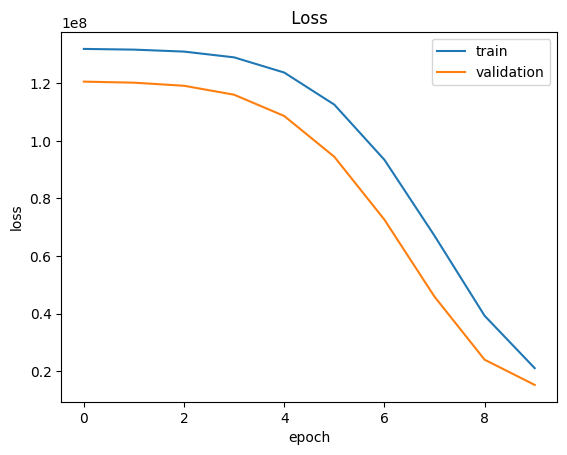

In [31]:
# plot train_loss vs validation_loss
import matplotlib.pyplot as plt
plt.plot(model_history.history['loss'])
plt.plot(model_history.history['val_loss'])

plt.title(" Loss ")
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','validation'])
plt.show()

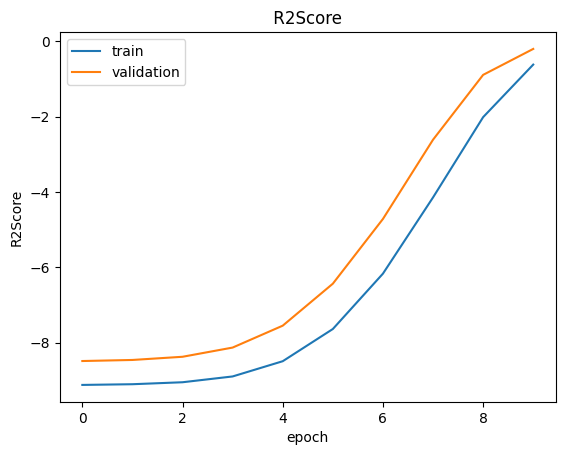

In [32]:
# plot train_r2score vs validation_r2score
import matplotlib.pyplot as plt
plt.plot(model_history.history['r2_score'])
plt.plot(model_history.history['val_r2_score'])

plt.title(" R2Score ")
plt.ylabel('R2Score')
plt.xlabel('epoch')
plt.legend(['train','validation'])
plt.show()